# Marketing Mix Analysis: Revenue, Media Spend and Adstock

Exploratory marketing-mix analysis of a consumer product sold across England, Scotland and Wales (Sep 2021 → 2024). Three sources are combined:

| File | Content |
|---|---|
| `data/sales.csv` | weekly units and price per region (ONS country codes) |
| `data/atl.json` | above-the-line spend: TV and outdoor |
| `data/digital.parquet` | daily digital spend |

The notebook computes revenue by region and year, studies weekly seasonality, relates revenue to media spend per channel, implements a geometric **adstock** transformation, chooses channel-specific decay rates and closes with notes on scaling the pipeline.

**Key findings:** England drives ~87% of revenue; digital spend tracks weekly revenue most closely (r = 0.94) with a short carryover, while TV shows weaker same-week correlation and a longer memory (chosen λ: digital 0.70, outdoor 0.80, TV 0.90).


## Data Loading

In [56]:
import pandas as pd
import numpy as np
from ydata_profiling import ProfileReport

### sales df

In [57]:
sales = pd.read_csv("data/sales.csv")  
print("sales:", sales.shape)
sales.head()

sales: (936, 4)


,date,region,metric,value
0,05-Sep-2021,E92000001,units,51673
1,12-Sep-2021,E92000001,units,40908
2,19-Sep-2021,E92000001,units,37678
3,26-Sep-2021,E92000001,units,32296
4,03-Oct-2021,E92000001,units,31219


In [58]:
print(sales.dtypes)
print(sales.isna().sum())

date      object
region    object
metric    object
value     object
dtype: object
date      0
region    0
metric    0
value     0
dtype: int64


In [59]:
sales["date"] = pd.to_datetime(sales["date"], dayfirst=True, errors="coerce")
sales["value"] = pd.to_numeric(sales["value"], errors="coerce")

map_regions = {
    "E92000001": "England",
    "S92000003": "Scotland",
    "W92000004": "Wales",
}

sales["region"] = sales["region"].replace(map_regions)

In [60]:
ProfileReport(sales)

#### atl df

In [61]:
atl = pd.read_json("data/atl.json")
print("atl:", atl.shape)
atl.head()

atl: (122, 4)


,date,region,channel,spend
0,2021-05-09,W92000004,tv,5000
1,2022-05-29,W92000004,tv,10000
2,2022-05-06,W92000004,tv,5000
3,2022-12-06,W92000004,tv,5000
4,2022-03-07,W92000004,tv,5000


In [62]:
print(atl.dtypes)
print(atl.isna().sum())

date       datetime64[ns]
region             object
channel            object
spend               int64
dtype: object
date       0
region     0
channel    0
spend      0
dtype: int64


In [70]:
atl["region"] = atl["region"].replace(map_regions)

In [71]:
ProfileReport(atl)

#### digital df

In [64]:
digital = pd.read_parquet("data/digital.parquet")
print("digital:", digital.shape)
digital.head()

digital: (3276, 4)


,date,region,channel,spend
0,2021-09-05,E92000001,digital,2349
1,2021-09-06,E92000001,digital,2579
2,2021-09-07,E92000001,digital,1973
3,2021-09-08,E92000001,digital,1487
4,2021-09-09,E92000001,digital,3034


In [65]:
print(digital.dtypes)
print(digital.isna().sum())

date       datetime64[ns]
region             object
channel            object
spend               int64
dtype: object
date       0
region     0
channel    0
spend      0
dtype: int64


In [72]:
digital["region"] = digital["region"].replace(map_regions)

In [73]:
ProfileReport(digital)

## 1. Annual revenue by region

In [67]:
sales_copy=sales.copy()
sales_copy["year"] = sales_copy["date"].dt.year
sales_copy.head()

,date,region,metric,value,year
0,2021-09-05,England,units,51673.0,2021
1,2021-09-12,England,units,40908.0,2021
2,2021-09-19,England,units,37678.0,2021
3,2021-09-26,England,units,32296.0,2021
4,2021-10-03,England,units,31219.0,2021


In [68]:
# for each year date and region, price and units pivottable
weekly_pivot=sales_copy.pivot_table(index=["year", "date", "region"],columns="metric", values="value", aggfunc="first").reset_index()

# drop rows with no price and units value
weekly_pivot = weekly_pivot.dropna(subset=["price", "units"])
weekly_pivot["revenue"] = weekly_pivot["price"] * weekly_pivot["units"]
weekly_pivot.head()

metric,year,date,region,price,units,revenue
0,2021,2021-09-05,England,8.50,51673.0,439220.50
1,2021,2021-09-05,Scotland,9.00,6083.0,54747.00
2,2021,2021-09-05,Wales,8.25,2533.0,20897.25
3,2021,2021-09-12,England,8.50,40908.0,347718.00
4,2021,2021-09-12,Scotland,9.00,5768.0,51912.00


In [69]:
# from weekly pivot table to yearly pivot table
year_pivot=weekly_pivot.groupby(["year", "region"])["revenue"].sum().unstack("region")

# showing in millions and to 2dp precision
year_pivot = (year_pivot / 1_000_000).round(2)

year_pivot.head()

region,England,Scotland,Wales
year,,,
2021,4.73,0.65,0.26
2022,22.44,2.44,1.15
2023,23.71,2.47,1.21
2024,17.74,1.68,0.87


## 2. Lowest-revenue year

### 2021 has the least revenue.

##### In 2021, three regions has a total of 5.64m of revenue in sales. That's mostly related to the sales data starting at 5 Sep 2021. So it only has 3 months worth of data. 

## 3. Decoding the region codes

The given region values are UK country codes of the home nations. E92000001 stands for England, S92000003 stands for Scotland and W92000004 stands for Wales. I have mapped them above for convenience.

## 4. Top region and why

In [74]:
overall_m = (year_pivot.sum(axis=0))
print(overall_m)           
print("Top region:", overall_m.idxmax())

region
England     68.62
Scotland     7.24
Wales        3.49
dtype: float64
Top region: England


#### England has the highest revenue. This is caused by England having the largest population and retail coverage in the UK. So market is bigger and it drives higher unit volume. Since more media activity is concentrated there, England generates the most sales and therefore revenue.

## 5. Weekly revenue trends

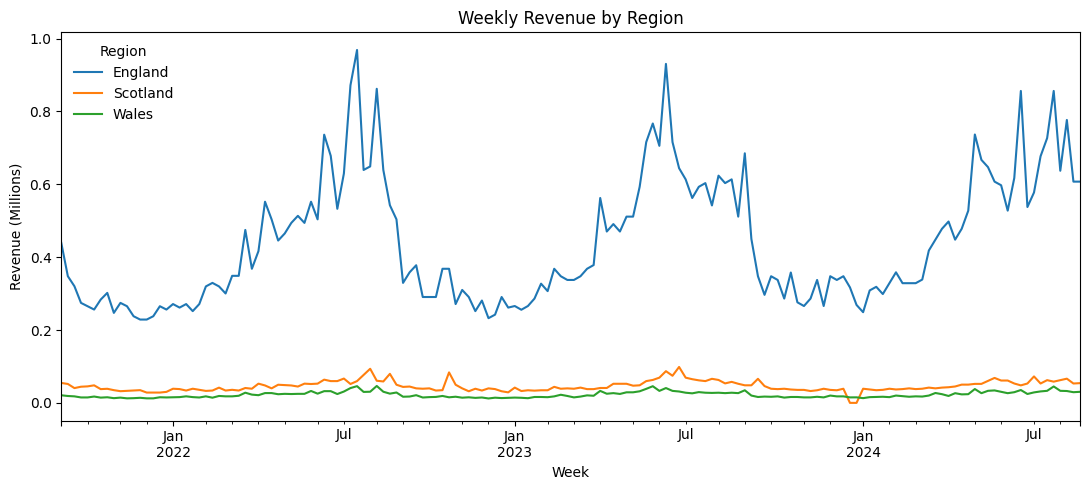

In [79]:
import matplotlib.pyplot as plt

%matplotlib inline

weekly_revenue_per_region=weekly_pivot.groupby(["date", "region"])["revenue"].sum().unstack("region").fillna(0).sort_index()

weekly_revenue_per_region = weekly_revenue_per_region / 1_000_000

ax = weekly_revenue_per_region.plot(figsize=(11, 5))
ax.set_title("Weekly Revenue by Region")
ax.set_xlabel("Week")
ax.set_ylabel("Revenue (Millions)")
ax.legend(title="Region", frameon=False)
plt.tight_layout()
plt.show()

### England dominates weekly revenue throughout. Rougly 10x of Scotland and 15x of Wales at peaks. 
### The three lines move together. Peaks and dips happen in the same weeks. 
### Clear sign of seasonality. Each Jan shows a dip after holiday, early summer shows the strongest peaks. 
### Occasional sharp weekly spikes, especially in England, shows campaign weeks or promotions. Scotland and Wales show the same pattern but in a smaller magnitude. 

## 6. Media spend by channel and region

In [100]:
# for tv and TV in channel column
atl["channel"] = atl["channel"].str.lower()  
atl.head()

,date,region,channel,spend
0,2021-05-09,Wales,tv,5000
1,2022-05-29,Wales,tv,10000
2,2022-05-06,Wales,tv,5000
3,2022-12-06,Wales,tv,5000
4,2022-03-07,Wales,tv,5000


In [101]:
digital.head()

,date,region,channel,spend
0,2021-09-05,England,digital,2349
1,2021-09-06,England,digital,2579
2,2021-09-07,England,digital,1973
3,2021-09-08,England,digital,1487
4,2021-09-09,England,digital,3034


In [102]:
# combine ATL + Digital into one media frame
media = pd.concat([atl[["date", "region", "channel", "spend"]], digital[["date", "region", "channel", "spend"]],],ignore_index=True)

# aggregate total spend by channel and region comibnations
totals = media.groupby(["channel", "region"], as_index=False)["spend"].sum()

In [103]:
totals.head()

,channel,region,spend
0,digital,England,3117817
1,digital,Scotland,310623
2,digital,Wales,161893
3,outdoor,England,1800000
4,outdoor,Scotland,360000


In [104]:
# pivoting the requested table and converting to millions and to 2dp
pivot = totals.pivot(index="channel", columns="region", values="spend").fillna(0)
pivot_m = (pivot / 1_000_000).round(2)

pivot_m.head()

region,England,Scotland,Wales
channel,,,
digital,3.12,0.31,0.16
outdoor,1.80,0.36,0.00
tv,2.90,0.18,0.14


## 7. Revenue vs. media spend

In [105]:
media.head()

,date,region,channel,spend
0,2021-05-09,Wales,tv,5000
1,2022-05-29,Wales,tv,10000
2,2022-05-06,Wales,tv,5000
3,2022-12-06,Wales,tv,5000
4,2022-03-07,Wales,tv,5000


In [106]:
# align to weekly
media["week"] = media["date"].dt.to_period("W-SUN").dt.start_time

In [107]:
# total media per week x region
media_week_total = (media.groupby(["week", "region"], as_index=False)["spend"].sum().rename(columns={"spend": "spend_total"}))

# per-channel media per week x region
media_week_channel = (media.groupby(["week", "region", "channel"], as_index=False)["spend"].sum())

In [108]:
weekly_pivot["week"] = weekly_pivot["date"].dt.to_period("W-SUN").dt.start_time

In [109]:
# merge with revenue
df_merged = weekly_pivot.merge(media_week_total, on=["week", "region"], how="left")
df_merged["spend_total"] = df_merged["spend_total"].fillna(0)
df_merged.head()

,year,date,region,price,units,revenue,week,spend_total
0,2021,2021-09-05,England,8.50,51673.0,439220.50,2021-08-30,2349
1,2021,2021-09-05,Scotland,9.00,6083.0,54747.00,2021-08-30,234
2,2021,2021-09-05,Wales,8.25,2533.0,20897.25,2021-08-30,104
3,2021,2021-09-12,England,8.50,40908.0,347718.00,2021-09-06,15152
4,2021,2021-09-12,Scotland,9.00,5768.0,51912.00,2021-09-06,2703


In [ ]:
# for channel-wise correlation, pivot channels into columns
chan_pivot = (
    media_week_channel
        .pivot_table(index=["week","region"], columns="channel", values="spend", aggfunc="sum")
        .fillna(0)
        .reset_index()
)

df_merged_channel = weekly_pivot.merge(chan_pivot, on=["week","region"], how="left").fillna(0)

# channel cols
channel_cols=["digital","outdoor","tv"]

In [111]:
df_merged_channel

,year,date,region,price,units,revenue,week,digital,outdoor,tv
0,2021,2021-09-05,England,8.50,51673.0,439220.50,2021-08-30,2349.0,0.0,0.0
1,2021,2021-09-05,Scotland,9.00,6083.0,54747.00,2021-08-30,234.0,0.0,0.0
2,2021,2021-09-05,Wales,8.25,2533.0,20897.25,2021-08-30,104.0,0.0,0.0
3,2021,2021-09-12,England,8.50,40908.0,347718.00,2021-09-06,15152.0,0.0,0.0
4,2021,2021-09-12,Scotland,9.00,5768.0,51912.00,2021-09-06,2703.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
461,2024,2024-08-18,Scotland,9.75,5454.0,53176.50,2024-08-12,2406.0,10000.0,10000.0
462,2024,2024-08-18,Wales,9.00,3256.0,29304.00,2024-08-12,1018.0,0.0,0.0
463,2024,2024-08-25,England,9.25,65668.0,607429.00,2024-08-19,34987.0,50000.0,0.0
464,2024,2024-08-25,Scotland,9.75,5558.0,54190.50,2024-08-19,2061.0,10000.0,10000.0


In [121]:
corr_by_region = (
    df_merged.groupby("region")
             .apply(lambda d: d["revenue"].corr(d["spend_total"]))
             .round(2)
             .rename("corr_rev_vs_total_spend")
)
print("Correlation (weekly revenue vs total media spend) by region:\n", corr_by_region)

Correlation (weekly revenue vs total media spend) by region:
 region
England     0.38
Scotland    0.38
Wales       0.33
Name: corr_rev_vs_total_spend, dtype: float64


### There is a moderate and consistent positive relationship accross regions. The correlation is between 0.33 and 0.38. 
### Higher spends weeks align with higher revenue. England and Scotland are similar, Wales is slightly lower. To see the lagged effects of channels like tv, testing 1-2 week lags would be sensible.

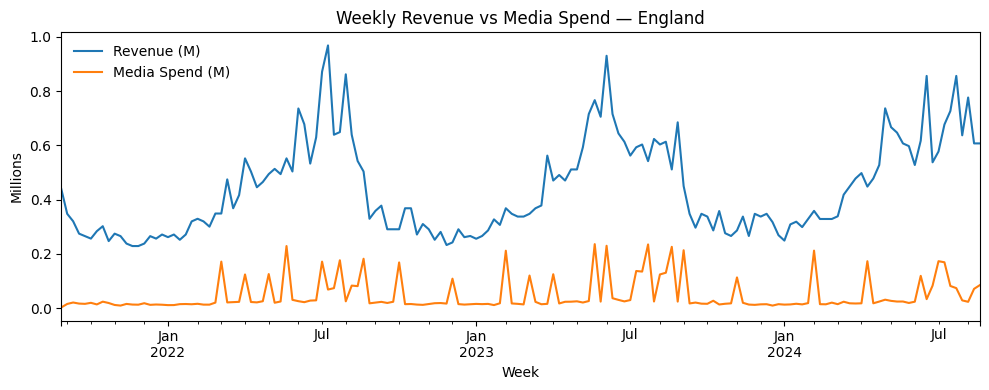

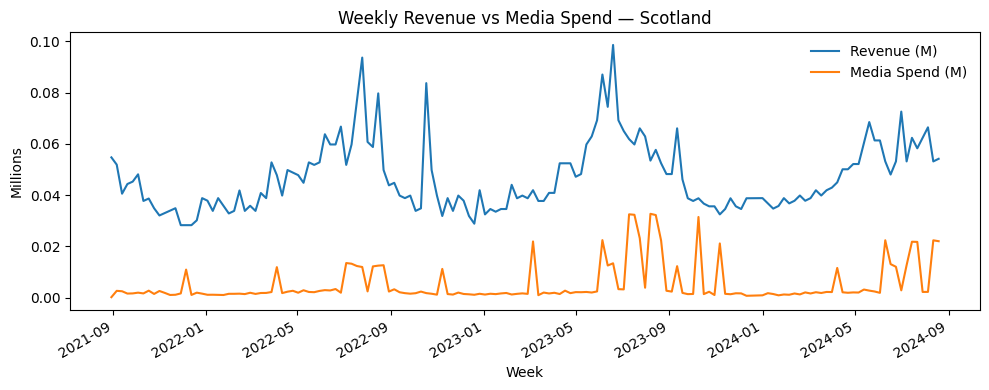

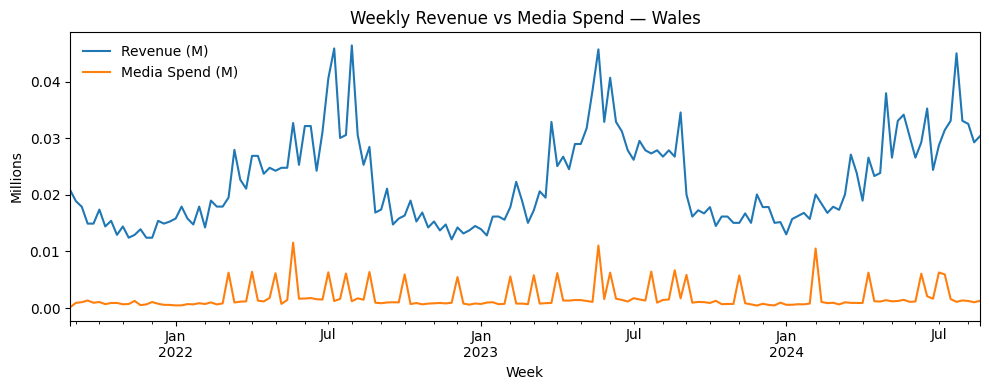

In [113]:
for region, g in df_merged.sort_values("week").groupby("region"):
    plot_df = g.set_index("week")[["revenue", "spend_total"]] / 1_000_000
    plot_df.columns = ["Revenue (M)", "Media Spend (M)"]
    ax = plot_df.plot(figsize=(10, 4), title=f"Weekly Revenue vs Media Spend — {region}")
    ax.set_xlabel("Week"); ax.set_ylabel("Millions")
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

### Weekly effect is stronger during campaign bursts (late spring/summer) and weaker in low spend times (Jan)
### Visuals sıggest 0-1 week lag
### Not every spikes moves revenue immediately, likely carrover.

In [122]:
# Pick channel columns automatically
exclude = {"week","region","date","price","units","revenue","spend_total","year"}
channel_cols = [c for c in df_merged_channel.columns if c not in exclude]

# Overall channel correlations (stack all regions/weeks)
overall_channel_corr = (
    df_merged_channel[["revenue"] + channel_cols]
      .corr()
      .loc["revenue", channel_cols]
      .sort_values(ascending=False)
      .round(2)
)
print("Correlation with revenue by channel (overall):\n", overall_channel_corr, "\n")


Correlation with revenue by channel (overall):
 digital    0.94
outdoor    0.42
tv         0.34
Name: revenue, dtype: float64 



### Overall 
#### Digital tracks revenue most closely (r=0.94). Fast, same-week response. 
#### Outdoor moderate (0.42)
#### TV weaker (0.34). likely more lag/carryover.

In [123]:
# Per-region channel correlations
corr_by_region_channel = (
    df_merged_channel.groupby("region")
                     .apply(lambda d: d[["revenue"] + channel_cols].corr()
                            .loc["revenue", channel_cols])
                     .round(2).fillna(0)
)
print("Correlation with revenue by channel (by region):\n", corr_by_region_channel)

Correlation with revenue by channel (by region):
 revenue   digital  outdoor    tv
region                          
England      0.69     0.38  0.18
Scotland     0.60     0.31  0.22
Wales        0.64     0.00  0.23


## 8. Adstock transformation

In [125]:
# adstock function
def adstock(spend, lam):
    lam = float(lam)
    x = np.asarray(spend, dtype=float)
    a = np.zeros_like(x)
    if x.size == 0:
        return a
    a[0] = x[0]
    for t in range(1, x.size):
        a[t] = x[t] + lam * a[t-1]
    return a


## 9. TV adstock in Scotland (λ = 0.75)

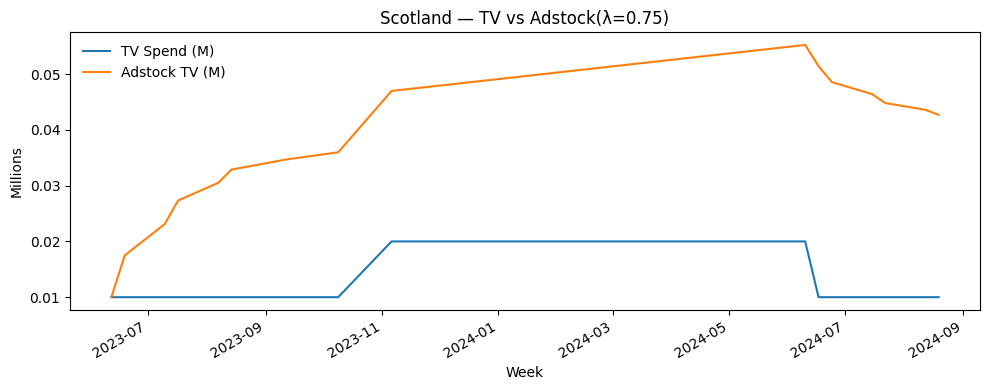

In [126]:
# Scotland weekly TV spend
tv_sc = (
    media_week_channel.query("region == 'Scotland' and channel == 'tv'")
    .sort_values("week")[["week", "spend"]]
    .set_index("week")["spend"]
)

# adstock with lambda 0.75
tv_sc_ad = pd.Series(adstock(tv_sc.values, 0.75), index=tv_sc.index, name="Adstock TV (λ=0.75)")

# plot (in millions)
plot_df = pd.concat([tv_sc/1_000_000, tv_sc_ad/1_000_000], axis=1)
plot_df.columns = ["TV Spend (M)", "Adstock TV (M)"]

ax = plot_df.plot(figsize=(10,4), title="Scotland — TV vs Adstock(λ=0.75)")
ax.set_xlabel("Week"); ax.set_ylabel("Millions")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 10. Digital adstock (λ = 0.9) and the behaviour of λ

In [128]:
media_week_channel.head()

,week,region,channel,spend
0,2021-05-03,England,tv,100000
1,2021-05-03,Scotland,outdoor,10000
2,2021-05-03,Wales,tv,5000
3,2021-08-30,England,digital,2349
4,2021-08-30,Scotland,digital,234


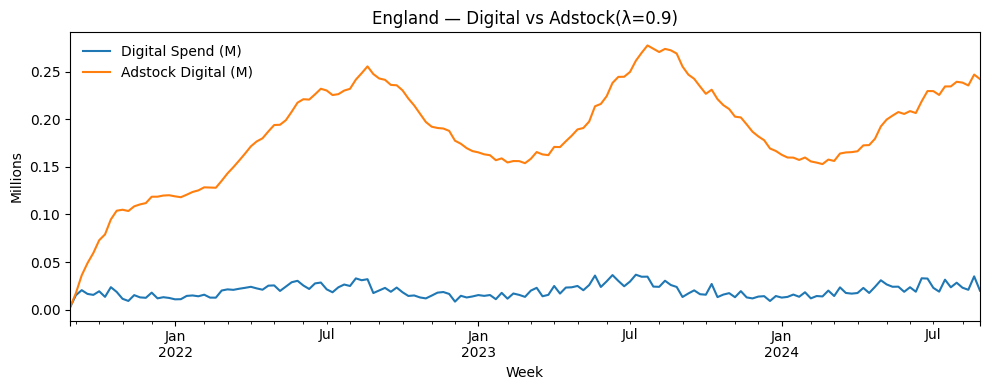

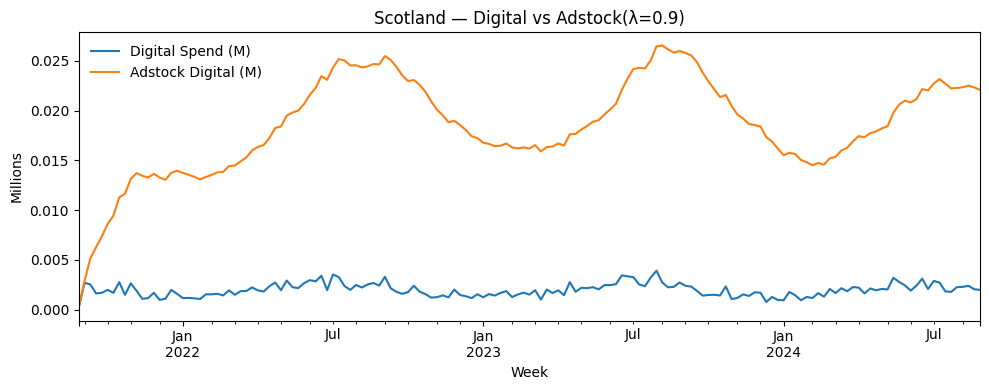

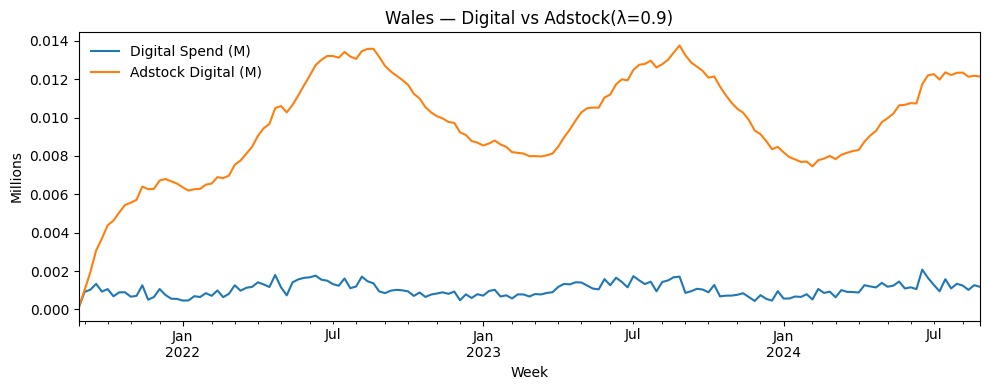

In [127]:
# loop all regions and plot digital vs adstock(digital, 0.9)
for region in sorted(media_week_channel["region"].unique()):
    dig = (
        media_week_channel.query("region == @region and channel == 'digital'")
        .sort_values("week")[["week", "spend"]]
        .set_index("week")["spend"]
        .fillna(0)
    )
    ad = pd.Series(adstock(dig.values, 0.9), index=dig.index, name="Adstock Digital (λ=0.9)")

    plot_df = pd.concat([dig/1_000_000, ad/1_000_000], axis=1)
    plot_df.columns = ["Digital Spend (M)", "Adstock Digital (M)"]

    ax = plot_df.plot(figsize=(10,4), title=f"{region} — Digital vs Adstock(λ=0.9)")
    ax.set_xlabel("Week"); ax.set_ylabel("Millions")
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

#### As λ → 1:
#### Memory becomes very long.  Adstock is almost same with cumulative sum.
#### Peaks broaden and persist, curve gets very smooth.

#### As t → ∞:
#### If spend stops, adstock decays to 0.
#### If spend is constant, adstock converges to a steady state.
#### With recurring/seasonal spend, adstock settles into a smoothed, lagged version of that pattern.

## 11. Channel-specific decay rates

#### Digital λ = 0.70. Half life 2 weeks. Since strongest same-week correlation. Fast response with short carryover.

#### TV λ = 0.90. Half  life 6 weeks. Because of weaker same-week correlation. Visible 0-1 week lag.

#### Outdoor λ = 0.80 Half life 3 weeks. Moderate correlation, shorter memory than TV.

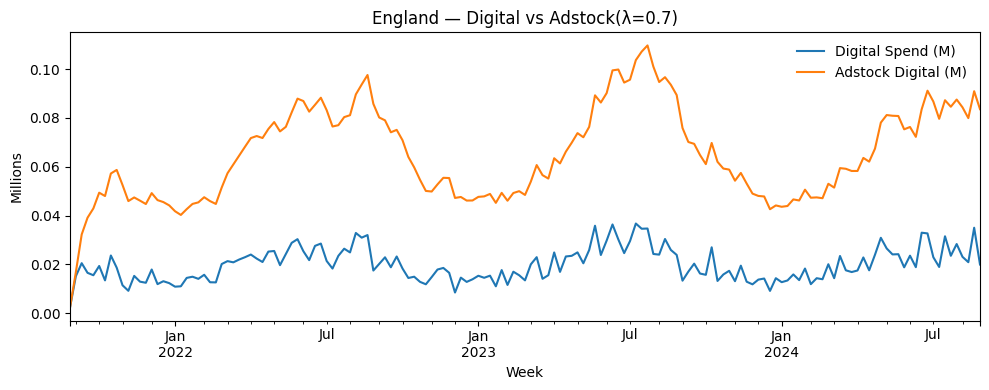

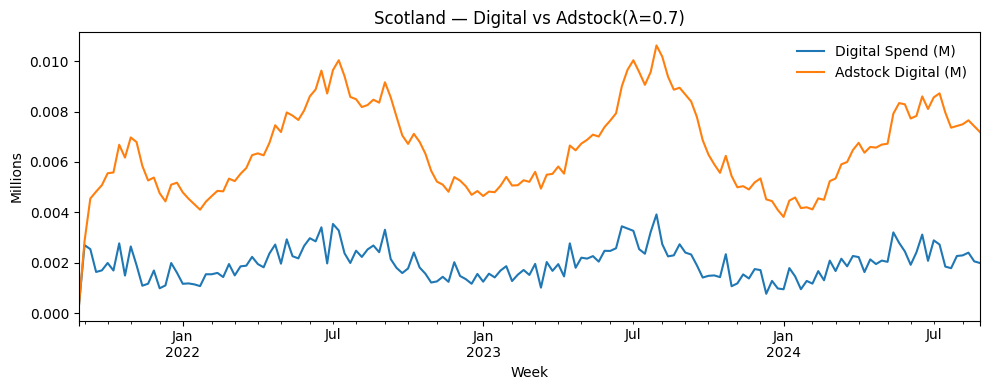

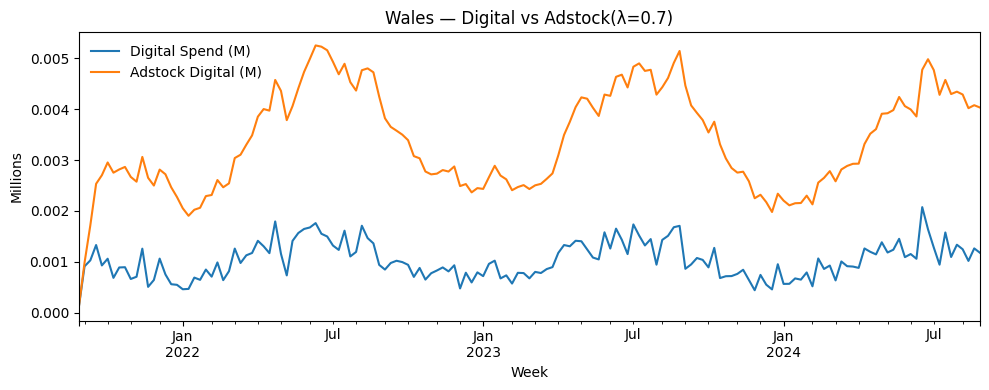

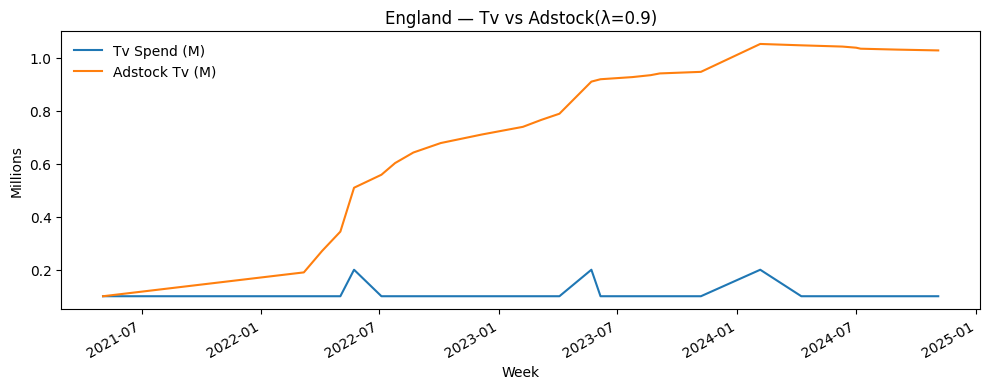

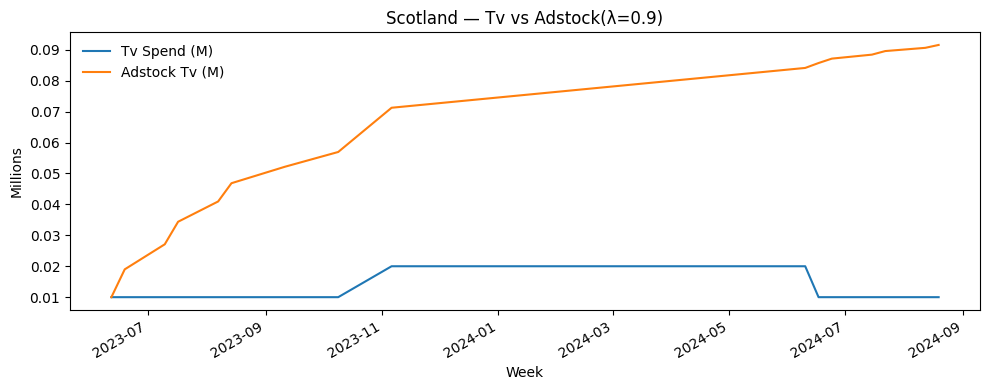

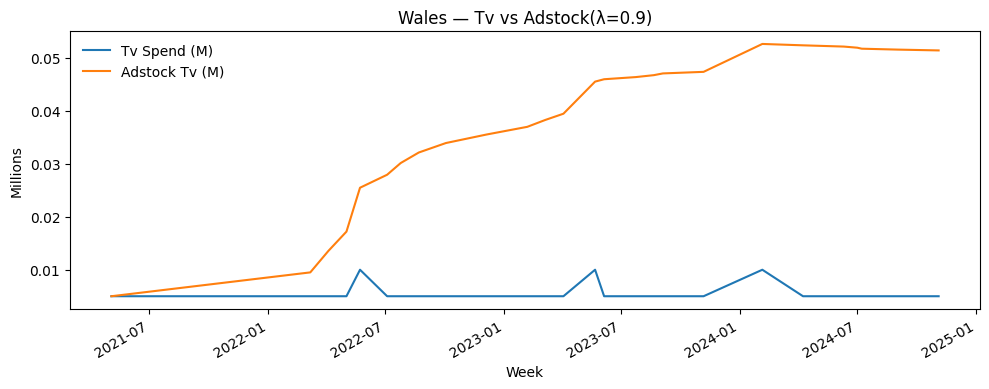

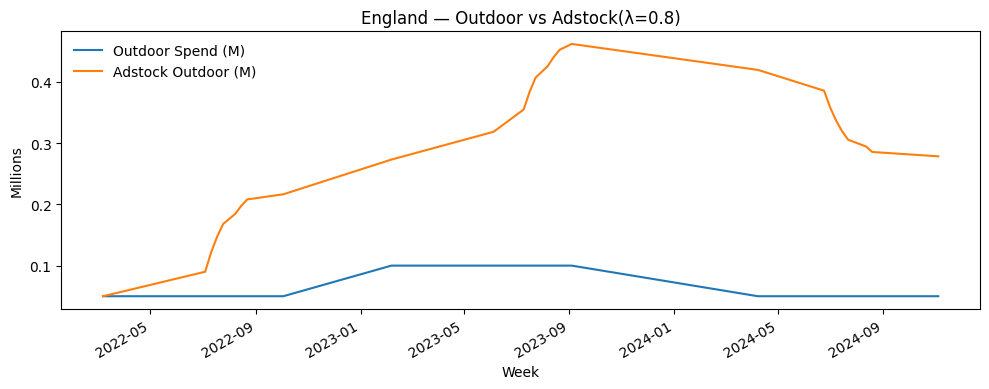

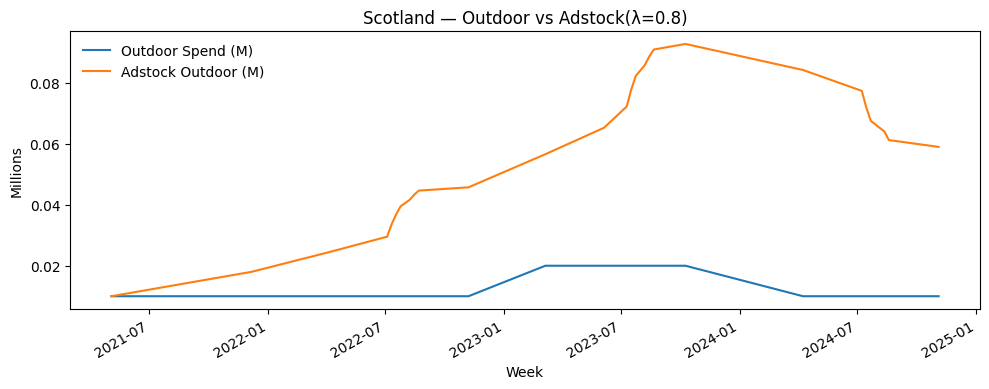

In [129]:
lambda_map = {"digital": 0.70, "tv": 0.90, "outdoor": 0.80}
regions = ["England", "Scotland", "Wales"]

for ch, lam in lambda_map.items():
    for region in regions:
        s = (
            media_week_channel.query("region == @region and channel == @ch")
            .sort_values("week")[["week", "spend"]]
            .set_index("week")["spend"]
            .fillna(0)
        )
        if s.empty:
            continue  # skip if channel not present for this region

        ad = pd.Series(adstock(s.values, lam), index=s.index, name=f"Adstock {ch} (λ={lam})")

        plot_df = pd.concat([s/1_000_000, ad/1_000_000], axis=1)
        plot_df.columns = [f"{ch.title()} Spend (M)", f"Adstock {ch.title()} (M)"]

        ax = plot_df.plot(figsize=(10, 4), title=f"{region} — {ch.title()} vs Adstock(λ={lam})")
        ax.set_xlabel("Week"); ax.set_ylabel("Millions")
        ax.legend(frameon=False)
        plt.tight_layout(); plt.show()

#### Digital’s adstock is tighter, TV/Outdoor show broader, longer-lasting curves. Matches the λ choices.

## 12. Scaling to production

#### For today’s data it’s fine, but as weeks × regions × channels explode, the groupby/pivot/merge bits become RAM-bound and slow.

#### Cost is roughly linear in rows with some sorting overhead; the wide pivots are what really hurt memory.

#### Adstock is O(G·C·T) (per region×channel×time). It’s okay now, but we should vectorize/parallelize it.

#### If this were prod enviornment
#### Switch from single machine pandas to Spark. store Parquet partitions.
#### Downcast dtypes, use categoricals, avoid super-wide pivots, pre-sort once, and cache weekly aggregates.

#### Implement adstock via NumPy/Numba in parallel.

#### Run as an incremental pipeline with simple time-based partitioning.